In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
latitude = [30,60]


In [5]:
ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_on_30-60N_temporal_corr_nonbinary.nc')['tp']

ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_off_30-60N_temporal_corr_nonbinary.nc')['tp']
ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle3_30-60N_temporal_corr_nonbinary.nc')['tp']
ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle4_1990-2020_30-60N_temporal_corr_nonbinary.nc')['tp']
icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle3_30-60N_temporal_corr_nonbinary.nc')['pr']
icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle4_30-60N_temporal_corr_nonbinary.nc')['pr']
# CESM2 is replaced by the CMIP6 models, loaded in the CMIP6 cells below
imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/imerg_30-60N_temporal_corr_nonbinary.nc')['precipitation']
#ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
#ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
#icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))



In [6]:
print(icon_cycle3)

<xarray.DataArray 'pr' (year: 5, cell: 2299980)> Size: 46MB
[11499900 values with dtype=float32]
Coordinates:
  * year     (year) int64 40B 2020 2021 2022 2023 2024
    lon      (cell) float64 18MB ...
    lat      (cell) float64 18MB ...
Dimensions without coordinates: cell


In [7]:
land_sea_ifs_high = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/ifs_hpx2048_lsm_30-60N.nc')['lsm']
land_sea_ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
land_sea_icon_zoom10 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
land_sea_icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
land_sea_imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
land_sea_imerg = land_sea_imerg.assign_coords(lat=imerg.lat, lon=imerg.lon)

ifs_on_land = ifs_on.where(land_sea_ifs_high > 0, np.nan)
ifs_off_land = ifs_off.where(land_sea_ifs_high > 0, np.nan)
ifs_cycle3_land = ifs_cycle3.where(land_sea_ifs_cycle3 > 0, np.nan)
ifs_cycle4_land = ifs_cycle4.where(land_sea_ifs_zoom9 > 0, np.nan)
icon_cycle3_land = icon_cycle3.where(land_sea_icon_zoom10 < 1, np.nan)
icon_cycle4_land = icon_cycle4.where(land_sea_icon_zoom9 < 1, np.nan)
imerg_land = imerg.where(land_sea_imerg < 100, np.nan)


In [8]:
print(icon_cycle3[0,:])

<xarray.DataArray 'pr' (cell: 2299980)> Size: 9MB
array([0.031069, 0.121736, 0.325214, ..., 0.04141 , 0.061037, 0.023385],
      dtype=float32)
Coordinates:
    year     int64 8B 2020
    lon      (cell) float64 18MB 56.16 55.99 56.07 56.12 ... 270.0 270.0 270.0
    lat      (cell) float64 18MB 30.04 30.04 30.04 30.09 ... 41.71 41.71 41.76
Dimensions without coordinates: cell


In [9]:
ifs_cycle3_land = ifs_cycle3_land.stack(sample=("year", "value"))
ifs_cycle4_land = ifs_cycle4_land.stack(sample=("year", "value"))
icon_cycle3_land = icon_cycle3_land.stack(sample=("year", "cell"))
icon_cycle4_land = icon_cycle4_land.stack(sample=("year", "cell"))
imerg_land = imerg_land.stack(sample=("year", "lat", "lon"))


In [10]:
ifs_on_land = ifs_on_land.where(~ifs_on_land.isnull(), drop=True)
ifs_off_land = ifs_off_land.where(~ifs_off_land.isnull(), drop=True)
ifs_cycle3_land = ifs_cycle3_land.where(~ifs_cycle3_land.isnull(), drop=True)
ifs_cycle4_land = ifs_cycle4_land.where(~ifs_cycle4_land.isnull(), drop=True)
icon_cycle3_land = icon_cycle3_land.where(~icon_cycle3_land.isnull(), drop=True)
icon_cycle4_land = icon_cycle4_land.where(~icon_cycle4_land.isnull(), drop=True)
imerg_land = imerg_land.where(~imerg_land.isnull(), drop=True)


In [11]:
#For IMERG weighting
# 1D cos(lat) weights
lat_rad = np.deg2rad(imerg.lat)
coslat = np.cos(lat_rad)                   # dims: ['lat']

w_lat = xr.DataArray(
    coslat,
    dims=['lat'],
    coords={'lat': imerg.lat}
)

# Broadcast to (lat, lon)
w_imerg_2d = w_lat.broadcast_like(land_sea_imerg)
# Mask to land only (same land mask you use for imerg_land)
w_imerg_2d = w_imerg_2d.where(land_sea_imerg < 100)
#w_imerg_2d = w_imerg_2d / w_imerg_2d.sum()
# Broadcast spatial weights to (year, lat, lon):
w_imerg_full = xr.DataArray(
    np.broadcast_to(w_imerg_2d.values, imerg.shape),
    dims=imerg.dims,
    coords=imerg.coords,
)
print(imerg.shape)
print(imerg.dims)
print(imerg.coords)
w_imerg_land = w_imerg_full.where(land_sea_imerg < 100, np.nan)

# Stack in exactly the same way as imerg_land
w_imerg_land = w_imerg_land.stack(sample=("year", "lat", "lon"))
print(w_imerg_land)
# Drop weights where the data is NaN to keep alignment
w_imerg_land = w_imerg_land.where(~imerg_land.isnull(), drop=True)
#w_imerg = w_imerg_land.values.ravel()


(10, 300, 3600)
('year', 'lat', 'lon')
Coordinates:
  * year     (year) int64 80B 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023
  * lon      (lon) float32 14kB -179.9 -179.9 -179.8 ... 179.8 179.8 179.9
  * lat      (lat) float32 1kB 30.05 30.15 30.25 30.35 ... 59.75 59.85 59.95
<xarray.DataArray (sample: 10800000)> Size: 43MB
array([nan, nan, nan, ..., nan, nan, nan], dtype=float32)
Coordinates:
  * sample   (sample) object 86MB MultiIndex
  * year     (sample) int64 86MB 2014 2014 2014 2014 ... 2023 2023 2023 2023
  * lat      (sample) float32 43MB 30.05 30.05 30.05 30.05 ... 59.95 59.95 59.95
  * lon      (sample) float32 43MB -179.9 -179.9 -179.8 ... 179.8 179.8 179.9


In [12]:
print(w_imerg_land)

<xarray.DataArray (sample: 5766389)> Size: 23MB
array([0.8655888 , 0.8655888 , 0.8655888 , ..., 0.50075555, 0.50075555,
       0.50075555], dtype=float32)
Coordinates:
  * sample   (sample) object 46MB MultiIndex
  * year     (sample) int64 46MB 2014 2014 2014 2014 ... 2023 2023 2023 2023
  * lat      (sample) float32 23MB 30.05 30.05 30.05 30.05 ... 59.95 59.95 59.95
  * lon      (sample) float32 23MB -115.8 -115.8 -115.6 ... 170.3 170.4 170.6


## CMIP6 multi-model distribution (replaces CESM2)

One file per member from `cmip6_temporal_autocorr_calc.py`: the lag-1 autocorrelation of daily precipitation for each May–Oct season and grid point, 30–60°N.
- **One member per model:** the first member of each model (`CMIP6_MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f), the same member as in the other CMIP6 notebooks.
- **Per model:** all years and land cells are pooled. Land is `sftlf > 0`, and each value gets a cos(lat) area weight, as for CESM2 before.
- **Equal model weights:** each model's weights are scaled to sum to 1, so the CMIP6 curve is the average of the per-model curves.
- **Grey band:** the range (`CMIP6_BAND_RANGE`) of the per-model KDE curves, with the same `bw_adjust` as the lines.
- **Models without an sftlf file** (BCC-CSM2-MR): the mask of `FALLBACK_MASK_MODEL` is used, matched to the nearest grid point.

In [23]:
import re
from collections import defaultdict

CMIP6_DIR           = '/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/CMIP6'   # output of cmip6_temporal_autocorr_calc.py
SFTLF_DIR           = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
CMIP6_EXPERIMENT    = 'historical'
CMIP6_YEARS         = None      # e.g. (1985, 2014) to use only those years; None = all years in the files
CMIP6_EXCLUDE       = []        # model names to leave out, e.g. ['BCC-CSM2-MR']
CMIP6_MEMBERS_PER_MODEL = 1     # first N members of each model (sorted r, i, p, f); None = all members
FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'   # mask for models without an sftlf file (BCC-CSM2-MR)
CMIP6_BAND_RANGE    = (10, 90)  # inter-model band, percentiles across models: (0, 100) = min-max, (10, 90) = 10-90%
CMIP6_BAND_COLOR    = '#888888' # grey, so it does not hide the pale IFS_2.8_deep_on line
CMIP6_BAND_ALPHA    = 0.15


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def weighted_quantile(values, weights, quantiles):
    sorter = np.argsort(values)
    v = np.asarray(values)[sorter]
    cumw = np.cumsum(np.asarray(weights)[sorter])
    cumw /= cumw[-1]
    return np.interp(quantiles, cumw, v)


# ── per model: land values of the first member(s), cos(lat) weights scaled to sum to 1 ──
pat = re.compile(rf'^temporal_corr_(?P<model>[^_]+)_{CMIP6_EXPERIMENT}_(?P<member>r\d+i\d+p\d+f\d+)_30-60N\.nc$')
member_files = defaultdict(list)
for f in os.listdir(CMIP6_DIR):
    if (m := pat.match(f)) and m['model'] not in CMIP6_EXCLUDE:
        member_files[m['model']].append((m['member'], f))
fallback_sftlf = xr.open_dataset(find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()

cmip6_models = {}   # model -> dict(values, weights): land values of all years and their normalised weights
for model in sorted(member_files, key=str.lower):
    chosen = sorted(member_files[model], key=lambda mf: member_sort_key(mf[0]))[:CMIP6_MEMBERS_PER_MODEL]
    vals, wts = [], []
    for mem, f in chosen:
        da = xr.open_dataset(os.path.join(CMIP6_DIR, f))['temporal_corr'].load()   # (year, lat, lon)
        if CMIP6_YEARS is not None:
            da = da.sel(year=slice(*CMIP6_YEARS))
        mask_path = find_sftlf(model)
        sftlf = nearest_regrid(xr.open_dataset(mask_path)['sftlf'].load() if mask_path else fallback_sftlf,
                               da.lat.values, da.lon.values)
        land = (sftlf > 0).values
        w2d = np.cos(np.deg2rad(da.lat.values))[:, None] * np.ones(da.sizes['lon'])
        v = da.values[:, land]                                          # (year, n_land)
        w = np.broadcast_to(w2d[land], v.shape)
        ok = np.isfinite(v)
        vals.append(v[ok])
        wts.append(w[ok])
    v, w = np.concatenate(vals), np.concatenate(wts)
    cmip6_models[model] = dict(values=v, weights=w / w.sum(), members=[mem for mem, _ in chosen])
    print(f"{model:14s} {', '.join(m for m, _ in chosen)}, {da.sizes['year']} years, {land.sum():5d} land cells, "
          f"median {weighted_quantile(v, w, 0.5):.3f}  mask: {os.path.basename(mask_path) if mask_path else FALLBACK_MASK_MODEL + ' (fallback)'}")

# ── multi-model sample: every model's weights sum to 1 / n_models ──
n_models = len(cmip6_models)
cmip6_land   = xr.DataArray(np.concatenate([d['values'] for d in cmip6_models.values()]), dims='sample')
w_cmip6_land = xr.DataArray(np.concatenate([d['weights'] / n_models for d in cmip6_models.values()]), dims='sample')
print(f'\n{n_models} models, {cmip6_land.size} values in total')


ACCESS-ESM1-5  r1i1p1f1, 165 years,  2720 land cells, median 0.285  mask: sftlf_fx_ACCESS-ESM1-5_historical_r1i1p1f1_native.nc
BCC-CSM2-MR    r1i1p1f1, 165 years,  4341 land cells, median 0.222  mask: MPI-ESM1-2-HR (fallback)
CAMS-CSM1-0    r2i1p1f1, 165 years,  4758 land cells, median 0.214  mask: sftlf_fx_CAMS-CSM1-0_1pctCO2_r2i1p1f1_native.nc
CanESM5        r1i1p2f1, 165 years,   858 land cells, median 0.262  mask: sftlf_fx_CanESM5_historical_r1i1p1f1_native.nc
CESM2          r1i1p1f1, 165 years,  5119 land cells, median 0.246  mask: sftlf_fx_CESM2_historical_r1i1p1f1_native.nc
CNRM-ESM2-1    r1i1p1f2, 165 years,  3442 land cells, median 0.282  mask: sftlf_fx_CNRM-ESM2-1_historical_r2i1p1f2_native.nc
EC-Earth3      r1i1p1f1, 165 years, 11444 land cells, median 0.235  mask: sftlf_fx_EC-Earth3_historical_r1i1p1f1_native.nc
FGOALS-g3      r1i1p1f1, 165 years,  1579 land cells, median 0.228  mask: sftlf_fx_FGOALS-g3_historical_r1i1p1f1_native.nc
GFDL-ESM4      r1i1p1f1, 165 years,  5256

In [24]:
print(np.median(imerg_land))


0.14155462


In [25]:
print(weighted_quantile(cmip6_land.values, w_cmip6_land.values, 0.5))   # CMIP6 median (area-weighted, equal model weights)

0.24783755838871002


In [26]:
print(np.median(ifs_off_land))

0.1541331774755011


In [27]:
print(np.median(ifs_on_land))

0.19237274542010363


In [28]:
print(np.median(icon_cycle4_land))

0.10381515519534798


In [29]:
print(np.median(icon_cycle3_land))

0.10835008


In [30]:
print(np.median(ifs_cycle3_land))

0.18535132136447577


In [31]:
print(np.median(ifs_cycle4_land))

0.1913475262854069


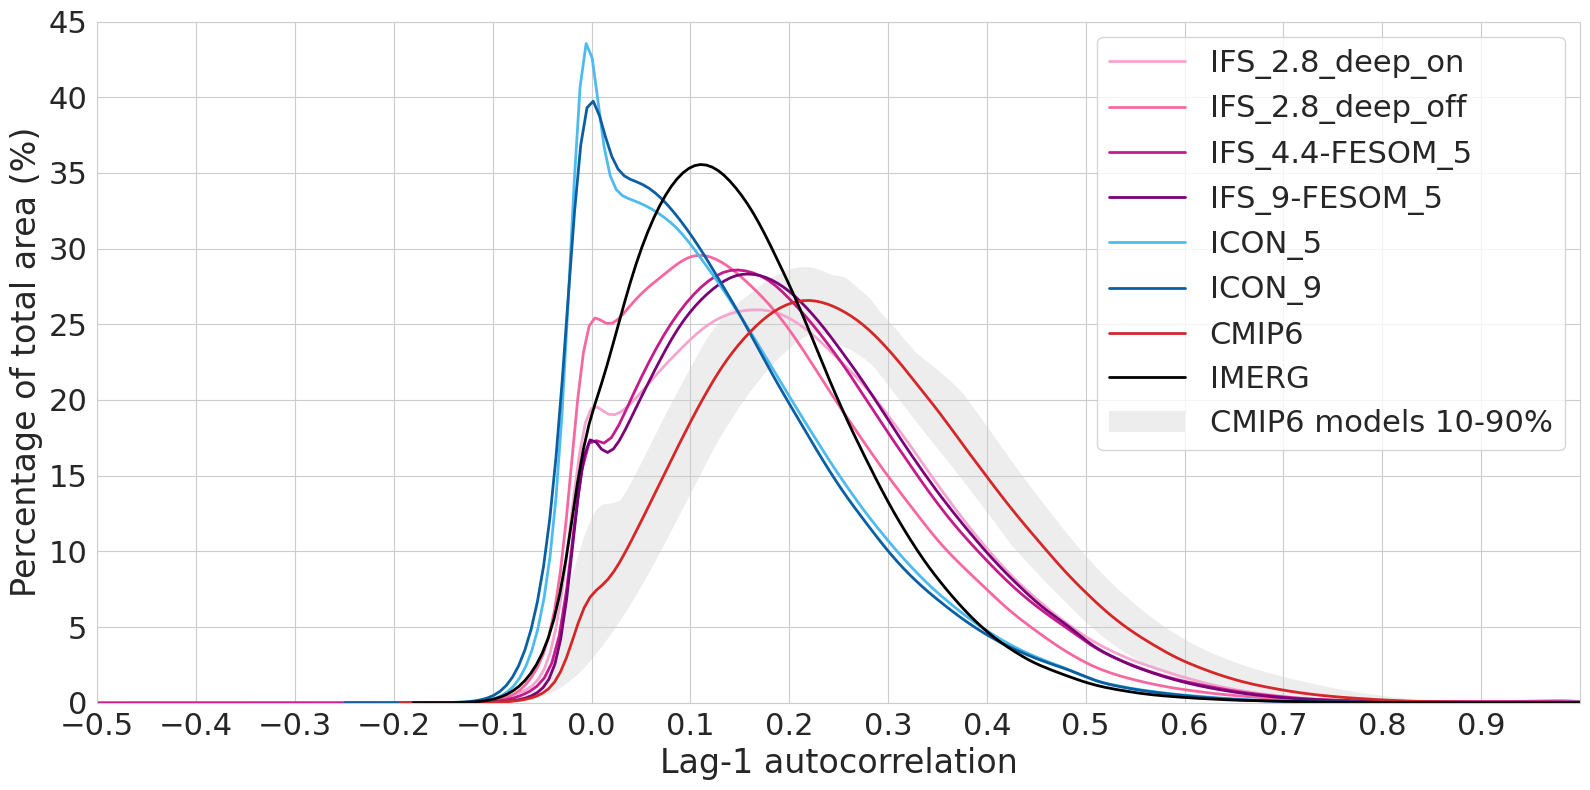

In [33]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = -0.5, 1


bin_width  = 0.10


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)

datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land,       ones_like_da(ifs_on_land),       '#F4A6CF', 'IFS_2.8_deep_on'),
    (ifs_off_land,      ones_like_da(ifs_off_land),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land,   ones_like_da(ifs_cycle3_land),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land,   ones_like_da(ifs_cycle4_land),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land,  ones_like_da(icon_cycle3_land),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land,  ones_like_da(icon_cycle4_land),  '#0A5FA3', 'ICON_9'),

    # CMIP6 multi-model & IMERG: area weights from above
    (cmip6_land,        w_cmip6_land,                    '#D62728', 'CMIP6'),
    (imerg_land,        w_imerg_land,                    '#000000',       'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 4b) CMIP6 inter-model band: range of the per-model KDE curves (same bandwidth rule and bw_adjust as
#     the lines), evaluated on the same x values as the CMIP6 line
from scipy.stats import gaussian_kde
cmip6_line = ax.get_lines()[[lab for *_, lab in datasets].index('CMIP6')]
x_grid = cmip6_line.get_xdata()
model_curves = []
for d in cmip6_models.values():
    k = gaussian_kde(d['values'], weights=d['weights'])
    k.set_bandwidth(k.factor * 2.0)                    # bw_adjust=2.0, as in sns.kdeplot above
    model_curves.append(k(x_grid) * 100 * bin_width)
band_lo, band_hi = np.percentile(np.array(model_curves), CMIP6_BAND_RANGE, axis=0)
ax.fill_between(x_grid, band_lo, band_hi, color=CMIP6_BAND_COLOR, alpha=CMIP6_BAND_ALPHA, linewidth=0, zorder=0)

# 5) Labels, limits, legend
xl = 'Lag-1 autocorrelation'
ax.set_ylim(0, 45)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 0.1)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]
legend_handles.append(Patch(facecolor=CMIP6_BAND_COLOR, alpha=CMIP6_BAND_ALPHA, edgecolor='none'))
legend_labels.append('CMIP6 model range' if tuple(CMIP6_BAND_RANGE) == (0, 100)
                     else f'CMIP6 models {CMIP6_BAND_RANGE[0]}-{CMIP6_BAND_RANGE[1]}%')

# then call legend with those handles
plt.legend(
    legend_handles,
    legend_labels,
    loc='upper right',
    prop={'size': 22},
    bbox_to_anchor=(1.0, 1.0),
    handlelength=2.5  # longer lines in legend if you like
)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_temporal_corr_nonbinary_histo_CMIP6mmm_band.pdf', format='pdf',bbox_inches='tight')

plt.show()